### Build A Basic Chatbot With Langgraph(GRAPH API)

In [39]:
from typing import Annotated 

from typing_extensions import TypedDict

from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages

In [40]:
class State(TypedDict):
    # Messages have the type "list". The `add_messages` function
    # in the annotation defines how this state key should be updated
    # (in this case, it appends messages to the list, rather than overwriting them)
    messages: Annotated[list, add_messages]

    ## add_messages - it is  a reducer that which does not replace the content of message variable instead it keeps the previous message and append a new message.
    ## Annoted - ## It's just a way to tell LangGraph: "for this field, use this rule when updating., The rule is "add_messages"

In [41]:
import os
from dotenv import load_dotenv
load_dotenv()

True

In [42]:
os.environ["GROQ_API_KEY"] = os.getenv("GROQ_API_KEY")

In [43]:
from langchain_groq import ChatGroq
from langchain.chat_models import init_chat_model

llm=ChatGroq(model="openai/gpt-oss-20b")
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.8.4', 'langchain': '1.5.2', 'langchain-groq': '1.2.1'}}, profile={'name': 'GPT OSS 20B', 'release_date': '2025-08-05', 'last_updated': '2025-08-05', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x0000022B65BB2350>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x0000022B65BB2AD0>, model_name='openai/gpt-oss-20b', model_kwargs={}, groq_api_key=SecretStr('**********'))

In [44]:
llm=init_chat_model("openai/gpt-oss-20b", model_provider="groq")
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.8.4', 'langchain': '1.5.2', 'langchain-groq': '1.2.1'}}, profile={'name': 'GPT OSS 20B', 'release_date': '2025-08-05', 'last_updated': '2025-08-05', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x0000022B65C26520>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x0000022B65C25BA0>, model_name='openai/gpt-oss-20b', model_kwargs={}, groq_api_key=SecretStr('**********'))

In [45]:
## Node Functionality
def chatbot(state:State):
    return {"messages" : [llm.invoke(state["messages"])]}

In [46]:
graph_builder = StateGraph(State)

## Adding node to graph
graph_builder.add_node("llmchatbot", chatbot)

## Adding the edges
graph_builder.add_edge(START, "llmchatbot") ## edge from start to llmchatbot
graph_builder.add_edge("llmchatbot", END)

## Compile the graph
graph = graph_builder.compile()

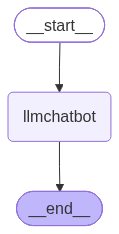

In [47]:
## Visualize the graph
from IPython.display import Image,display

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    pass

In [48]:
response=graph.invoke({"messages":"Hi"})

In [49]:
response

{'messages': [HumanMessage(content='Hi', additional_kwargs={}, response_metadata={}, id='6639d51a-d4e9-4dad-8d7d-dabe5c09c9df'),
  AIMessage(content='Hello! How can I help you today?', additional_kwargs={'reasoning_content': 'User says "Hi". They want a greeting response. We should respond politely.'}, response_metadata={'token_usage': {'completion_tokens': 35, 'prompt_tokens': 72, 'total_tokens': 107, 'completion_time': 0.035515545, 'completion_tokens_details': {'reasoning_tokens': 17}, 'prompt_time': 0.003362961, 'prompt_tokens_details': None, 'queue_time': 0.285778339, 'total_time': 0.038878506}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_d3e146e1a5', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a20704-1f64-75b4-8e6a-1e1948b1c1a7-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 72, 'output_tokens': 35, 'total_tokens': 107, 'output_token_details': {'reasoning': 17}})]}

In [50]:
response["messages"]

[HumanMessage(content='Hi', additional_kwargs={}, response_metadata={}, id='6639d51a-d4e9-4dad-8d7d-dabe5c09c9df'),
 AIMessage(content='Hello! How can I help you today?', additional_kwargs={'reasoning_content': 'User says "Hi". They want a greeting response. We should respond politely.'}, response_metadata={'token_usage': {'completion_tokens': 35, 'prompt_tokens': 72, 'total_tokens': 107, 'completion_time': 0.035515545, 'completion_tokens_details': {'reasoning_tokens': 17}, 'prompt_time': 0.003362961, 'prompt_tokens_details': None, 'queue_time': 0.285778339, 'total_time': 0.038878506}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_d3e146e1a5', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a20704-1f64-75b4-8e6a-1e1948b1c1a7-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 72, 'output_tokens': 35, 'total_tokens': 107, 'output_token_details': {'reasoning': 17}})]

In [51]:
response["messages"][-1]

AIMessage(content='Hello! How can I help you today?', additional_kwargs={'reasoning_content': 'User says "Hi". They want a greeting response. We should respond politely.'}, response_metadata={'token_usage': {'completion_tokens': 35, 'prompt_tokens': 72, 'total_tokens': 107, 'completion_time': 0.035515545, 'completion_tokens_details': {'reasoning_tokens': 17}, 'prompt_time': 0.003362961, 'prompt_tokens_details': None, 'queue_time': 0.285778339, 'total_time': 0.038878506}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_d3e146e1a5', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a20704-1f64-75b4-8e6a-1e1948b1c1a7-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 72, 'output_tokens': 35, 'total_tokens': 107, 'output_token_details': {'reasoning': 17}})

In [52]:
response["messages"][-1].content

'Hello! How can I help you today?'

In [53]:
for event in graph.stream({"messages" : "Hi! How are you"}):
    for value in event.values():
        print(value["messages"][-1].content)

Hi there! I’m doing great—thanks for asking. How about you? Anything interesting on your mind today?


### Chatbot With Tool

In [54]:
import os
from dotenv import load_dotenv
load_dotenv()
os.environ["TAVILY_API_KEY"] = os.getenv("TAVILY_API_KEY")

In [55]:
from langchain_tavily import TavilySearch

## tool 1 - tavily that makes a google search.
tool = TavilySearch(max_results=2)
tool.invoke("What is langGraph")

{'query': 'What is langGraph',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://www.ibm.com/think/topics/langgraph',
   'title': 'What is LangGraph? | IBM',
   'content': 'LangGraph, created by LangChain, is an open source AI agent framework designed to build, deploy and manage complex generative AI agent workflows. It provides a set of tools and libraries that enable users to create, run and optimize large language models (LLMs) in a scalable and efficient manner. At its core, LangGraph uses the power of graph-based architectures to model and manage the intricate relationships between various components of an AI agent workflow. [...] LangGraph illuminates the processes within an AI workflow, allowing full transparency of the agent’s state. Within LangGraph, the “state” feature serves as a memory bank that records and tracks all the valuable information processed by the AI system. It’s similar to a digital notebook where the system captures an

In [56]:
## tool 2 - Custom multipky function
def multiply(a:int, b:int)->int:
    """Multiply a and b

    Args:
    a (int): first int
    b (int): second int

    Returns:
        int: output int
    """
    return a*b

In [57]:
tools = [tool, multiply]

In [58]:
## binding tools with llm

llm_with_tool = llm.bind_tools(tools)

In [59]:
llm_with_tool

_ChatModelBinding(bound=ChatGroq(metadata={'lc_versions': {'langchain-core': '1.8.4', 'langchain': '1.5.2', 'langchain-groq': '1.2.1'}}, profile={'name': 'GPT OSS 20B', 'release_date': '2025-08-05', 'last_updated': '2025-08-05', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x0000022B65C26520>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x0000022B65C25BA0>, model_name='openai/gpt-oss-20b', model_kwargs={}, groq_api_key=SecretStr('**********')), kwargs={'tools': [{'type': 'function', 'function': {'name': 'tavily_search', 'description': 'A search engine optimized for co

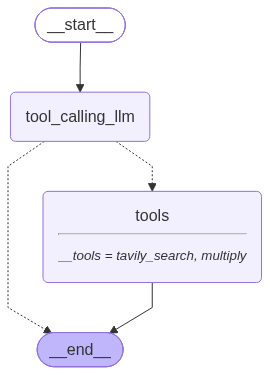

In [60]:
## StateGrpah - Graph API
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

## Node definition
def tool_calling_llm(state: State): ## state class we have previously defined at the start of this notebook.
    return {"messages" : [llm_with_tool.invoke(state["messages"])]}

## Graph
builder = StateGraph(State)
builder.add_node("tool_calling_llm", tool_calling_llm)
builder.add_node("tools", ToolNode(tools))


## Connecting the edges with node
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
        # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
        # If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
        tools_condition
)
builder.add_edge("tools", END)

## compile with graph

graph= builder.compile()

from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))


In [61]:
## Tool call for tool1 -Tavily
response = graph.invoke({"messages":"what is the recent AI news"})

In [62]:
response['messages']

[HumanMessage(content='what is the recent AI news', additional_kwargs={}, response_metadata={}, id='3d37832a-925f-4375-9487-dc05bf085000'),
 AIMessage(content='', additional_kwargs={'reasoning_content': 'User: "what is the recent AI news". We need up-to-date news. Must browse. Use tavily_search. Let\'s search for recent AI news.', 'tool_calls': [{'id': 'fc_401871d0-d31c-4fc0-aed7-af8e3b8df089', 'function': {'arguments': '{"query":"recent AI news","search_depth":"basic","topic":"news"}', 'name': 'tavily_search'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 69, 'prompt_tokens': 348, 'total_tokens': 417, 'completion_time': 0.075150613, 'completion_tokens_details': {'reasoning_tokens': 33}, 'prompt_time': 0.017583397, 'prompt_tokens_details': None, 'queue_time': 0.048753153, 'total_time': 0.09273401}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_c5a89987dc', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None, 'mo

In [63]:
response['messages'][-1].content

'{"query": "recent AI news", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.youtube.com/watch?v=eDiQNFa-zYg&vl=en-US", "title": "AI News: The Only 6 Stories Worth Knowing This Week", "content": "# AI News: The Only 6 Stories Worth Knowing This Week\\n## Channel: Matt Wolfe (verified)\\n1.04M subscribers\\n2.3K likes\\n\\n### Description\\n134,466 views\\nPosted: 2026-10-30\\nCheck out Warp Factories here: \\n\\nThis week’s biggest AI news: OpenAI’s GPT-6.1 Terra brings faster computer use at a lower API cost, and Google’s Genie 4 brings real-time AI worlds to life. We’re also covering Gemini 4 Carbon, Kimi K3.1 Pro, and Anthropic’s IPO filing.\\n\\nSharing the latest news and advancements in AI [...] ### Chapters\\n[0:00] Anthropic\'s $2 Trillion IPO\\n[6:17] Warp Factories (Sponsor)\\n[7:23] OpenAI\'s GPT-6.1 Tera\\n[12:00] Google\'s Gemini 4 Carbon\\n[13:39] Kimi K3.1 Pro: Powerful Open-Weight AI\\n[18:07] Testing Google\'s Genie 4 World M

In [64]:
for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

what is the recent AI news
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_401871d0-d31c-4fc0-aed7-af8e3b8df089)
 Call ID: fc_401871d0-d31c-4fc0-aed7-af8e3b8df089
  Args:
    query: recent AI news
    search_depth: basic
    topic: news
================================= Tool Message =================================
Name: tavily_search

{"query": "recent AI news", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.youtube.com/watch?v=eDiQNFa-zYg&vl=en-US", "title": "AI News: The Only 6 Stories Worth Knowing This Week", "content": "# AI News: The Only 6 Stories Worth Knowing This Week\n## Channel: Matt Wolfe (verified)\n1.04M subscribers\n2.3K likes\n\n### Description\n134,466 views\nPosted: 2026-10-30\nCheck out Warp Factories here: \n\nThis week’s biggest AI news: OpenAI’s GPT-6.1 Terra brings faster

In [65]:
## Tool call for tool2 - multiply custom function
response=graph.invoke({"messages":"What is 5 multiplied by 2"})
for m in response['messages']:
    m.pretty_print()


================================ Human Message =================================

What is 5 multiplied by 2
================================== Ai Message ==================================
Tool Calls:
  multiply (fc_3c302e05-432d-4cc5-9c30-4a4843783713)
 Call ID: fc_3c302e05-432d-4cc5-9c30-4a4843783713
  Args:
    a: 5
    b: 2
================================= Tool Message =================================
Name: multiply

10


In [66]:
## for the below the our llm can make tolol call for only Tavily but cant make call for the multiply function.
## to solve this we use react agent
response=graph.invoke({"messages":"Give me the recent ai news and then multiply 5 by 10"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

Give me the recent ai news and then multiply 5 by 10
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_b3c412ba-ea27-41c2-92f4-66a18a7e63b8)
 Call ID: fc_b3c412ba-ea27-41c2-92f4-66a18a7e63b8
  Args:
    query: recent AI news 2026
    search_depth: advanced
    topic: news
================================= Tool Message =================================
Name: tavily_search

{"query": "recent AI news 2026", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.youtube.com/watch?v=ikAr4KegMeM", "title": "AI News for October 2026 (in 12 minutes)", "content": "The AI news from October 2026 worth your time, in 12 minutes. Google's own AI ate into its search ads, and Alphabet had its worst day ever. Four tech giants spent nearly $209 billion in one quarter. AI found critical flaws in PHP, and governments pulled th

### ReAct Agent Architecture

just replace end with tool_calling_llm

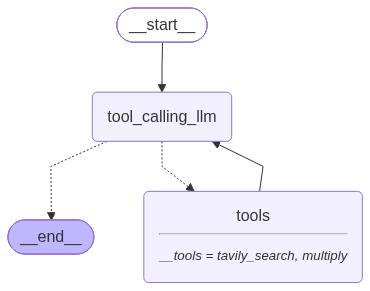

In [67]:
## StateGrpah - Graph API
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

## Node definition
def tool_calling_llm(state: State): ## state class we have previously defined at the start of this notebook.
    return {"messages" : [llm_with_tool.invoke(state["messages"])]}

## Graph
builder = StateGraph(State)
builder.add_node("tool_calling_llm", tool_calling_llm)
builder.add_node("tools", ToolNode(tools))


## Connecting the edges with node
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
        # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
        # If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
        tools_condition
)
builder.add_edge("tools", "tool_calling_llm") ## replace the END

## compile with graph

graph= builder.compile()

from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))


In [68]:
response=graph.invoke({"messages":"Give me the recent ai news and then multiply 5 by 10"})
for m in response['messages']:
    m.pretty_print()

## from the below output we can see thet the llm can make multiple tool call using react agent

================================ Human Message =================================

Give me the recent ai news and then multiply 5 by 10
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_33e69dfe-26a3-444f-8f62-e4a10964aef8)
 Call ID: fc_33e69dfe-26a3-444f-8f62-e4a10964aef8
  Args:
    query: recent AI news 2026 November
    search_depth: basic
    topic: news
================================= Tool Message =================================
Name: tavily_search

{"query": "recent AI news 2026 November", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.youtube.com/watch?v=1t0kdeDCHJ0", "title": "Episode 230: Weekly AI News Summary - 1 November 2026", "content": "In today’s Weekly AI News Summary.. Anthropic’s financial disclosures reveal the enormous costs of competing in the AI race, while growing concerns over AI spending, corporate debt and disappointing returns trigger a major sello

## Adding Memory In Agentic Graph

In [69]:
response=graph.invoke({"messages":"Hello my name is Ram"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

Hello my name is Ram
================================== Ai Message ==================================

Hello Ram! 👋 How can I help you today?


In [70]:
response=graph.invoke({"messages":"What is my name"})
for m in response['messages']:
    m.pretty_print()

## from the below output we can see that the llm forgets the name....so it has no memory...we have to implement it.


================================ Human Message =================================

What is my name
================================== Ai Message ==================================

I’m sorry—I don’t have any record of your name. If you let me know, I’ll remember it for this conversation.


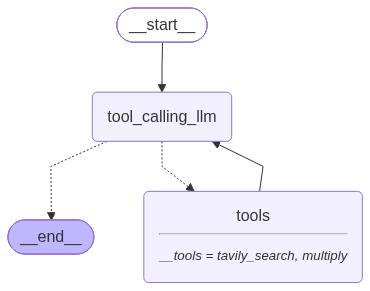

In [71]:
## just add the the checkpointer in builder.compile.
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition
from langgraph.checkpoint.memory import MemorySaver

memory = MemorySaver()

## Node definition
def tool_calling_llm(state:State):
    return {"messages":[llm_with_tool.invoke(state["messages"])]}

## Grpah
builder=StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

## Add Edges
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition
)
builder.add_edge("tools","tool_calling_llm")

## compile the graph
graph=builder.compile(checkpointer=memory) ## just add this checkpointer to implement memory.

from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [72]:
config = {"configurable" : {"thread_id" : "1"}}

reponse = graph.invoke({"messages" : "Hi my name is Ram"}, config=config)

response

{'messages': [HumanMessage(content='What is my name', additional_kwargs={}, response_metadata={}, id='0f31645c-3c97-431e-a084-5e886b21b390'),
  AIMessage(content='I’m sorry—I don’t have any record of your name. If you let me know, I’ll remember it for this conversation.', additional_kwargs={'reasoning_content': 'User asks "What is my name". We don\'t know their name. We can respond that we don\'t know.'}, response_metadata={'token_usage': {'completion_tokens': 59, 'prompt_tokens': 346, 'total_tokens': 405, 'completion_time': 0.060332335, 'completion_tokens_details': {'reasoning_tokens': 23}, 'prompt_time': 0.005498426, 'prompt_tokens_details': {'cached_tokens': 256}, 'queue_time': 0.367335352, 'total_time': 0.065830761}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_e11c8bbf69', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a20704-85da-724a-8ab5-2cf6b28389d3-0', tool_calls=[], invalid_tool_calls=[], usag

In [73]:
response['messages'][-1].content

'I’m sorry—I don’t have any record of your name. If you let me know, I’ll remember it for this conversation.'

In [74]:
response=graph.invoke({"messages":"Hey what is my name"},config=config)

print(response['messages'][-1].content)

You’re Ram.


In [75]:
response=graph.invoke({"messages":"Hey do you remember mmy name"},config=config)

print(response['messages'][-1].content)

Yes, you mentioned that your name is Ram. Let me know how I can help you!


### Streaming

In [76]:
from langgraph.checkpoint.memory import MemorySaver
memory=MemorySaver()

In [77]:
def superbot(state:State):
    return {"messages":[llm.invoke(state['messages'])]}

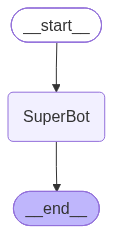

In [78]:
graph=StateGraph(State)

## node
graph.add_node("SuperBot",superbot)
## Edges

graph.add_edge(START,"SuperBot")
graph.add_edge("SuperBot",END)


graph_builder=graph.compile(checkpointer=memory)


## Display
from IPython.display import Image, display
display(Image(graph_builder.get_graph().draw_mermaid_png()))

In [ ]:
## Invocation

config = {"configurable": {"thread_id": "1"}}


graph_builder.invoke({'messages':"Hi,My name is Krish And I like cricket"},config)

### Streaming 
Methods: .stream() and astream()

- These methods are sync and async methods for streaming back results.

Additional parameters in streaming modes for graph state

- **values** : This streams the full state of the graph after each node is called.
- **updates** : This streams updates to the state of the graph after each node is called.

In [80]:
# Create a thread
config = {"configurable": {"thread_id": "3"}}

for chunk in graph_builder.stream({'messages':"Hi,My name is Krish And I like cricket"},config,stream_mode="updates"):
    print(chunk)

{'SuperBot': {'messages': [AIMessage(content='Hey Krish! 👋🏼 Great to meet a fellow cricket fan. I can chat about the latest matches, discuss players, help you crunch some cricket stats, or even dive into coding and math if you’re curious. What’s on your mind today—any particular team or topic you’d like to explore?', additional_kwargs={'reasoning_content': 'We have a user message: "Hi,My name is Krish And I like cricket". The system message says we should respond in a friendly tone, ask clarifying question if needed, provide a brief summary of what we can do. We can mention that we can do math, coding, etc. We can ask about preferences or what they\'d like to talk about. We should not mention policies. Let\'s respond friendly.'}, response_metadata={'token_usage': {'completion_tokens': 157, 'prompt_tokens': 82, 'total_tokens': 239, 'completion_time': 0.166975656, 'completion_tokens_details': {'reasoning_tokens': 85}, 'prompt_time': 0.006482905, 'prompt_tokens_details': None, 'queue_time

In [81]:
for chunk in graph_builder.stream({'messages':"Hi,My name is Krish And I like cricket"},config,stream_mode="values"):
    print(chunk)

{'messages': [HumanMessage(content='Hi,My name is Krish And I like cricket', additional_kwargs={}, response_metadata={}, id='81d96e20-c9db-4eb7-a6a8-5ad237d48b61'), AIMessage(content='Hey Krish! 👋🏼 Great to meet a fellow cricket fan. I can chat about the latest matches, discuss players, help you crunch some cricket stats, or even dive into coding and math if you’re curious. What’s on your mind today—any particular team or topic you’d like to explore?', additional_kwargs={'reasoning_content': 'We have a user message: "Hi,My name is Krish And I like cricket". The system message says we should respond in a friendly tone, ask clarifying question if needed, provide a brief summary of what we can do. We can mention that we can do math, coding, etc. We can ask about preferences or what they\'d like to talk about. We should not mention policies. Let\'s respond friendly.'}, response_metadata={'token_usage': {'completion_tokens': 157, 'prompt_tokens': 82, 'total_tokens': 239, 'completion_time': 

In [84]:
# Create a thread
config = {"configurable": {"thread_id": "4"}}

for chunk in graph_builder.stream({"messages" : "Hi, My name is Ram and I like Cricket"}, config, stream_mode="updates"):
    print(chunk)

{'SuperBot': {'messages': [AIMessage(content='Hey Ram! 👋 It’s great to meet a cricket fan. Which teams or players do you follow most? 🏏', additional_kwargs={'reasoning_content': 'User says: "Hi, My name is Ram and I like Cricket". We need to respond. The user says name Ram. They like cricket. We can respond with friendly greeting, ask about cricket. No policy issues.'}, response_metadata={'token_usage': {'completion_tokens': 81, 'prompt_tokens': 81, 'total_tokens': 162, 'completion_time': 0.085498965, 'completion_tokens_details': {'reasoning_tokens': 46}, 'prompt_time': 0.003825844, 'prompt_tokens_details': None, 'queue_time': 0.154432354, 'total_time': 0.089324809}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_e23fc997ca', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a20707-fb6f-7437-b596-fecd5dd3d955-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 81, 'output_tokens': 81, 't

In [85]:
for chunk in graph_builder.stream({'messages':"I also like football"},config,stream_mode="values"):
    print(chunk)

{'messages': [HumanMessage(content='Hi, My name is Ram and I like Cricket', additional_kwargs={}, response_metadata={}, id='2d3bb2d1-ff8a-4212-9ad5-1efdbc81e59e'), AIMessage(content='Hey Ram! 👋 It’s great to meet a cricket fan. Which teams or players do you follow most? 🏏', additional_kwargs={'reasoning_content': 'User says: "Hi, My name is Ram and I like Cricket". We need to respond. The user says name Ram. They like cricket. We can respond with friendly greeting, ask about cricket. No policy issues.'}, response_metadata={'token_usage': {'completion_tokens': 81, 'prompt_tokens': 81, 'total_tokens': 162, 'completion_time': 0.085498965, 'completion_tokens_details': {'reasoning_tokens': 46}, 'prompt_time': 0.003825844, 'prompt_tokens_details': None, 'queue_time': 0.154432354, 'total_time': 0.089324809}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_e23fc997ca', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--0

In [86]:
config = {"configurable": {"thread_id": "5"}}

async for event in graph_builder.astream_events({"messages":["Hi My name is Krish and I like to play cricket"]},config,version="v2"):
    print(event)

{'event': 'on_chain_start', 'data': {'input': {'messages': ['Hi My name is Krish and I like to play cricket']}}, 'name': 'LangGraph', 'tags': [], 'run_id': '01a20708-3353-7741-a66a-aa76d1f98d40', 'metadata': {'thread_id': '5', 'ls_integration': 'langgraph'}, 'parent_ids': []}
{'event': 'on_chain_start', 'data': {'input': {'messages': [HumanMessage(content='Hi My name is Krish and I like to play cricket', additional_kwargs={}, response_metadata={}, id='feeff234-ff8b-461c-8b31-9f139bb2ee71')]}}, 'name': 'SuperBot', 'tags': ['graph:step:1'], 'run_id': '01a20708-3367-725f-90b2-81e7f8cea498', 'metadata': {'thread_id': '5', 'ls_integration': 'langgraph', 'langgraph_step': 1, 'langgraph_node': 'SuperBot', 'langgraph_triggers': ('branch:to:SuperBot',), 'langgraph_path': ('__pregel_pull', 'SuperBot'), 'langgraph_checkpoint_ns': 'SuperBot:d5c2252d-2ae6-de43-c9f9-93c785f099b6'}, 'parent_ids': ['01a20708-3353-7741-a66a-aa76d1f98d40']}
{'event': 'on_chat_model_start', 'data': {'input': {'messages':